# imports

In [95]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [96]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [97]:
# specific
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

In [98]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_worm_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../../worm-control/src/utils_worm_control/read_utils.py'>

# setup

In [99]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [100]:
# specific

# model_variant = 'ss, ns'
organism = 'worm'
manual = False
full = False

In [101]:
file_ids = list(range(0, 30+1))
# file_ids = [19]

# load

In [102]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filenames = analysis_utils.read_filenames(organism, file_ids)

In [103]:
neuron_numbers = list()
for file_id in file_ids:
	filename, traces, eigenworms, discrete_states, timestamps, aux = analysis_utils.read_data(organism, file_id)
	neuron_numbers.append(traces.values.shape[1])
filename, traces, eigenworms, discrete_states, timestamps, aux = None, None, None, None, None, None

# scores (ns)

In [104]:
significant_neurons_ns = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_significant_neurons(filename, 'ns')
	significant_neurons_ns.append(neuron_scores_significant)

/tmp/ipykernel_44166/2395184773.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])


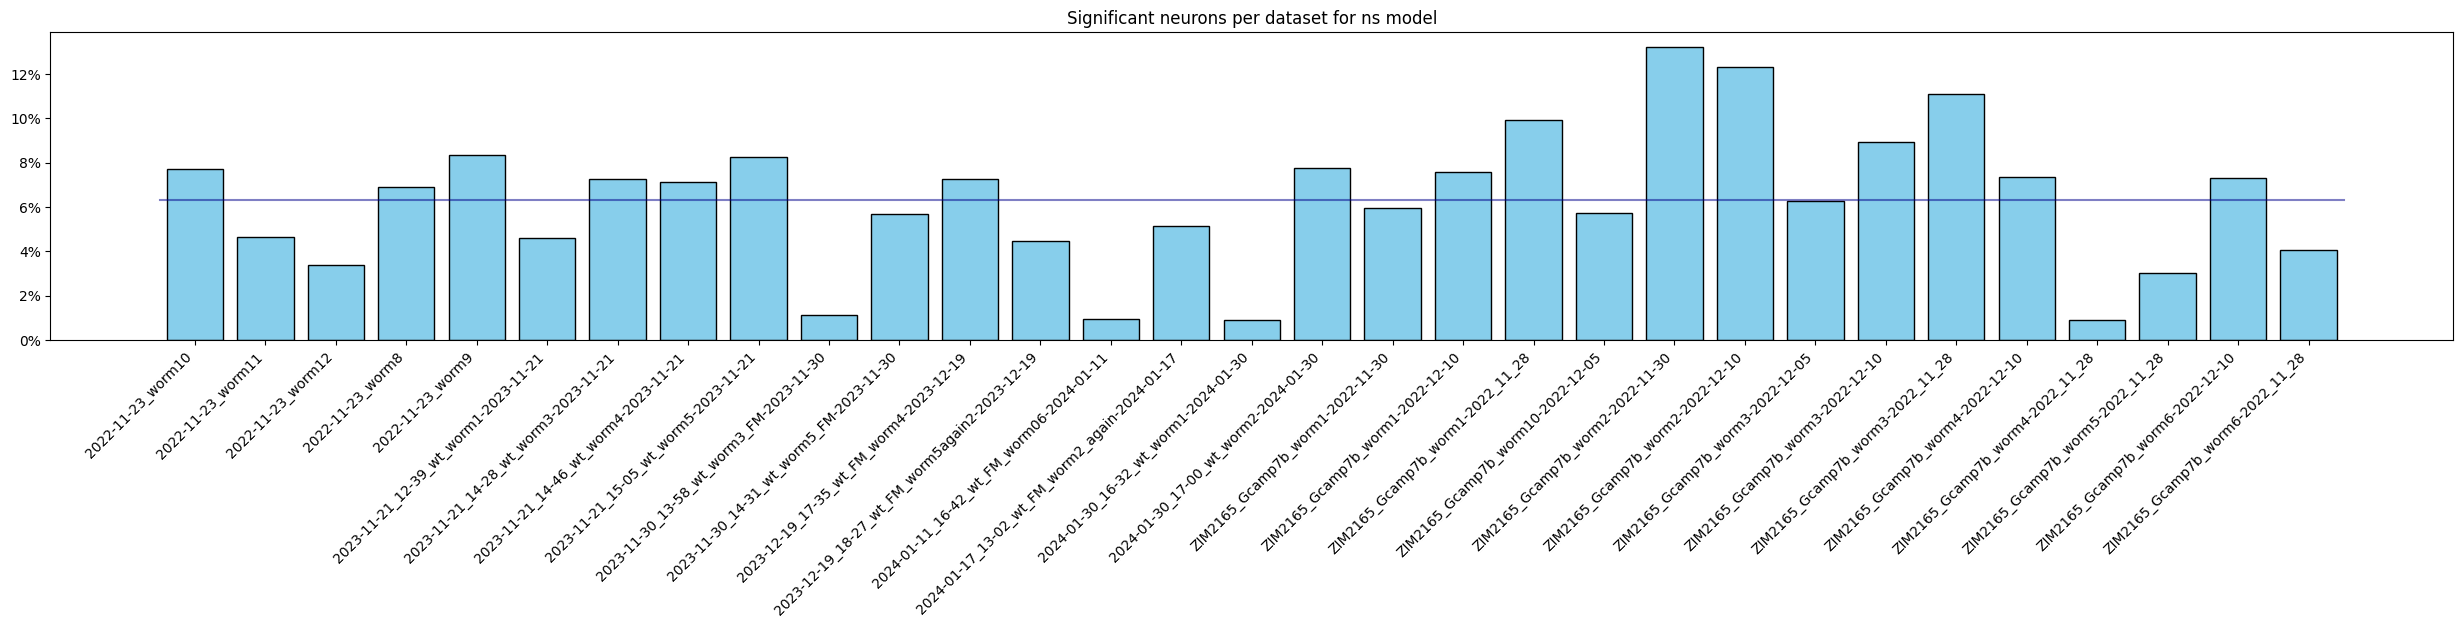

In [105]:
plt.figure(figsize=(1*len(filenames), 4))
values = [neurons.values.shape[1] / n * 100 for neurons, n in zip(significant_neurons_ns, neuron_numbers)]
mean = np.mean(values)
plt.bar(np.arange(len(filenames)), values, color='skyblue' , edgecolor='black')
plt.plot([-0.5, len(filenames)-1 + 0.5], [mean, mean], color='darkblue', alpha=0.5)
plt.xticks(np.arange(len(filenames)), filenames, rotation=45, ha='right')
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])
plt.title('Significant neurons per dataset for ns model')
if save:
	plt.savefig('../../out/plots/scores/significant_neurons_ns.png', bbox_inches='tight')

# scores (ss)

In [106]:
significant_neurons_ss = list()
for filename in filenames:
	neuron_scores_significant = analysis_utils.get_significant_neurons(filename, 'ss')
	significant_neurons_ss.append(neuron_scores_significant)

/tmp/ipykernel_44166/540903555.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])


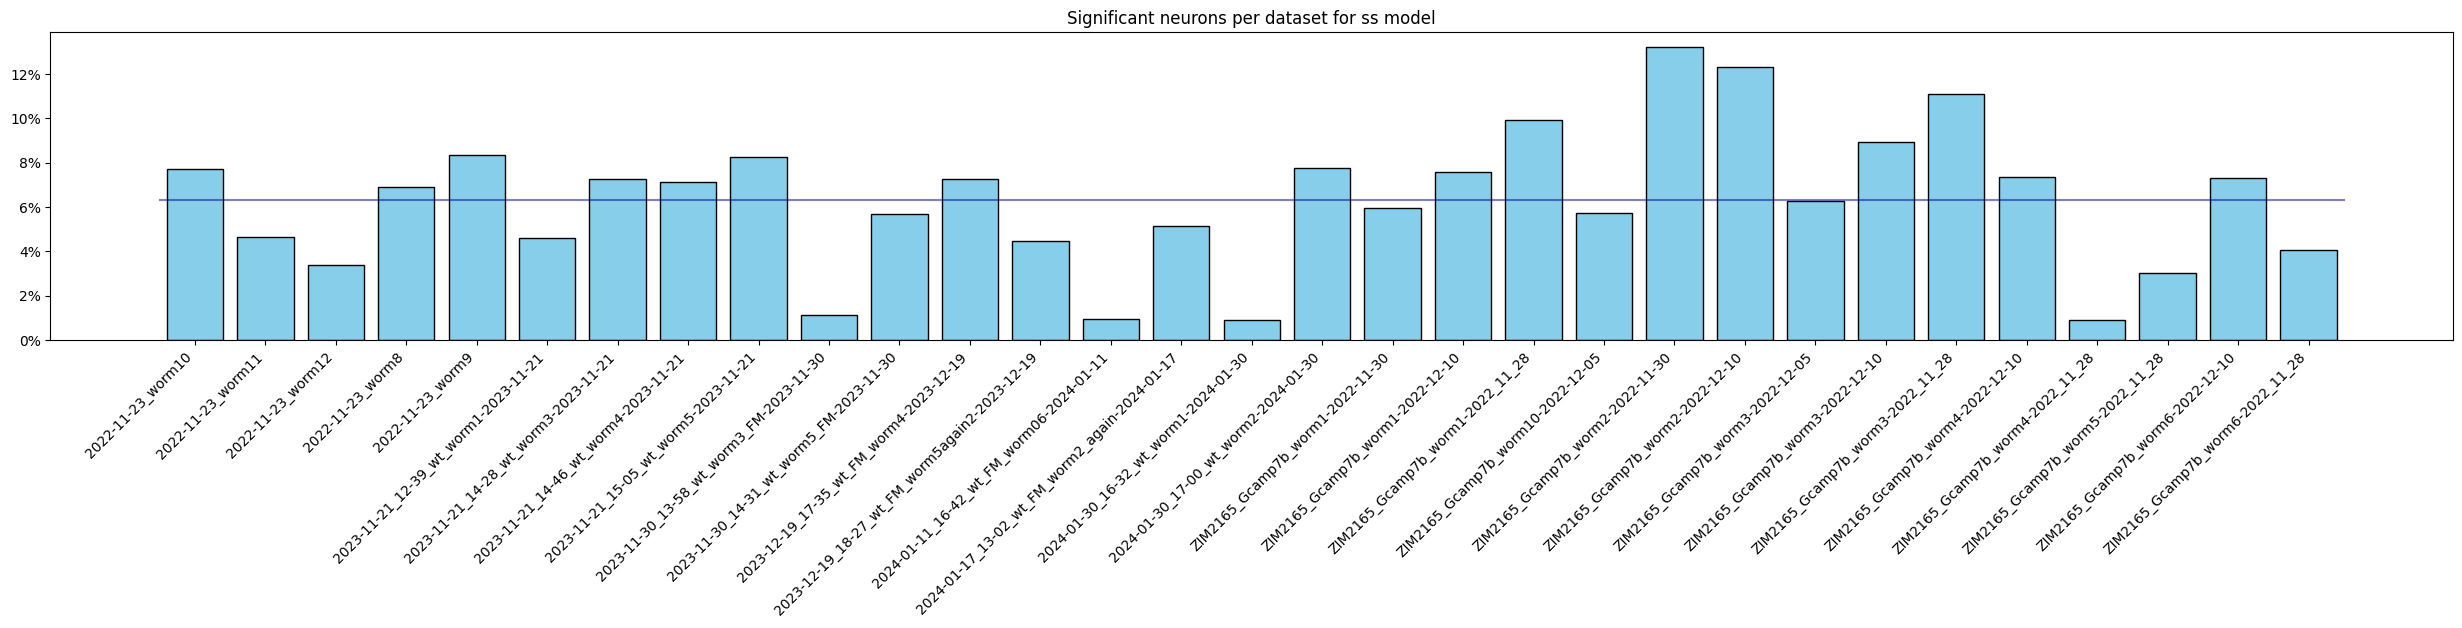

In [107]:
plt.figure(figsize=(1*len(filenames), 4))
values = [neurons.values.shape[1] / n * 100 for neurons, n in zip(significant_neurons_ns, neuron_numbers)]
mean = np.mean(values)
plt.bar(np.arange(len(filenames)), values, color='skyblue' , edgecolor='black')
plt.plot([-0.5, len(filenames)-1 + 0.5], [mean, mean], color='darkblue', alpha=0.5)
plt.xticks(np.arange(len(filenames)), filenames, rotation=45, ha='right')
yticks = plt.gca().get_yticks()
plt.gca().set_yticklabels([f'{int(t)}%' for t in yticks])
plt.title('Significant neurons per dataset for ss model')
if save:
	plt.savefig('../../out/plots/scores/significant_neurons_ss.png', bbox_inches='tight')